<a href="https://colab.research.google.com/github/PrabhuYaswanth/CIFAR10_Image_Classification_using_ANN/blob/main/ANN_and_GPU_Benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

In [3]:
tf.config.experimental.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'),
 PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [4]:
(X_train,y_train),(X_test,y_test)=tf.keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3351s 20us/step


In [5]:
X_train.shape

(50000, 32, 32, 3)

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]], dtype=uint8)
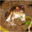

In [6]:
X_train[0]

In [7]:
X_train[0].shape

(32, 32, 3)

In [8]:
y_train[0:5]

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [9]:
# Visualizing X_train
def plot_sample(index):
  plt.figure(figsize=(10,1))
  plt.imshow(X_train[index])

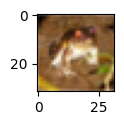

In [10]:
plot_sample(0)

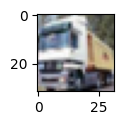

In [11]:
plot_sample(1)

In [12]:
# Defining class for convenient purpose
#ploting y_train

classes=["airplaine","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

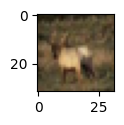

In [13]:
plot_sample(3) #X_train

In [14]:
y_train[3]  #Y_train

array([4], dtype=uint8)

In [15]:
print(type(classes))

<class 'list'>


In [16]:
classes[y_train[3][0]]  # to see What this is

'deer'

Scaling

In [17]:
X_train_scaled=X_train/255
X_test_scaled=X_test/255

In [18]:
X_train.shape  # shape does not changes, It sclaes the value for better prediction

(50000, 32, 32, 3)

One Hot Encoding For classification.There is API for converting outputs to categorical

In [37]:
y_train_categorical = keras.utils.to_categorical(y_train, num_classes=10).astype('float32')

In [39]:
y_test_categorical = keras.utils.to_categorical(y_test, num_classes=10).astype('float32')

In [41]:
print(y_train_categorical.shape)
print(y_train_categorical.dtype)

(50000, 10)
float32


In [42]:
y_train[:5]

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [44]:
model=keras.Sequential([
    keras.layers.Flatten(input_shape=(32,32,3)),
    keras.layers.Dense(3000,activation='relu'),
    keras.layers.Dense(1000,activation='relu'),
    keras.layers.Dense(10,activation='sigmoid')
])
model.compile(
    optimizer='SGD',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train_scaled,y_train_categorical)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.3565 - loss: 1.8133


In [52]:
model.predict(X_test_scaled)[0] # 0th output

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([0.43724298, 0.59098   , 0.554599  , 0.841752  , 0.32638872,
       0.7748467 , 0.68602383, 0.2706101 , 0.67514795, 0.12268157],
      dtype=float32)

In [53]:
import numpy as np
np.argmax(model.predict(X_test_scaled)[0]) # 0th output

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


np.int64(3)

In [54]:
classes[np.argmax(model.predict(X_test_scaled)[0])]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


'cat'

Performance Test

In [57]:
def get_model():
    model = keras.Sequential([
        keras.layers.Flatten(input_shape=(32, 32, 3)),
        keras.layers.Dense(3000, activation='relu'),
        keras.layers.Dense(1000, activation='relu'),
        keras.layers.Dense(10, activation='sigmoid')
    ])

    model.compile(
        optimizer='SGD',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [62]:
# To run on
with tf.device('/CPU:0'):
  cpu_model=get_model()
  cpu_model.fit(X_train_scaled,y_train_categorical,epochs=1)


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 105s 67ms/step - accuracy: 0.3488 - loss: 1.8172


In [63]:
 #To run on GPU
with tf.device('/GPU:0'):
  gpu_model=get_model()
  gpu_model.fit(X_train_scaled,y_train_categorical,epochs=1)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.3544 - loss: 1.8114
